In [6]:
import sklearn
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [7]:
from sklearn import datasets

In [8]:
diab=datasets.load_diabetes()
print(diab.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [9]:
X= diab.data
Y=diab.target

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train,X_test, Y_train,Y_test = train_test_split(X,Y,train_size=0.8,random_state=43) 

In [12]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

In [13]:
model = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)

In [14]:
model.fit(X_train,Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [15]:
Y_pred = model.predict(X_test)
Y_pred 

array([140.01651 ,  99.037926, 188.61841 , 238.82205 , 208.83282 ,
       107.33026 , 203.01717 , 141.42426 , 112.38146 , 212.47678 ,
        51.64407 , 238.33014 , 102.006   ,  85.40118 , 147.28767 ,
       191.15285 , 190.30486 , 186.84421 , 235.26692 , 137.50803 ,
       128.86511 , 131.54962 , 220.35297 , 211.9191  , 116.694046,
       109.2735  , 229.17505 ,  89.39842 ,  74.02381 , 178.01479 ,
       215.46947 ,  76.18847 , 144.7378  , 109.714005, 179.52263 ,
       125.42297 ,  98.16386 , 105.62817 ,  89.275444, 103.96535 ,
       133.22916 , 187.81711 , 101.2915  , 159.70465 , 304.24625 ,
       112.68093 ,  44.579357, 260.58554 ,  89.057976, 103.782295,
       244.1977  , 228.64226 , 189.49408 ,  75.178246,  86.88869 ,
       176.82315 , 118.38799 , 182.51416 , 269.07697 , 272.12946 ,
       243.76039 , 184.06282 , 120.0305  , 129.67854 , 229.79803 ,
       127.54377 ,  95.91183 , 101.18778 ,  67.433426, 249.64034 ,
        65.905   , 184.37218 , 132.3118  , 159.47815 ,  85.916

In [16]:
mean_absolute_error(Y_test,Y_pred)

48.25011208352078

In [17]:
mean_squared_error(Y_test,Y_pred)

3508.098480442885

In [18]:
np.sqrt(mean_squared_error(Y_test,Y_pred))

np.float64(59.22920293607609)

In [19]:
r2_score(Y_test,Y_pred)

0.43785775242802505

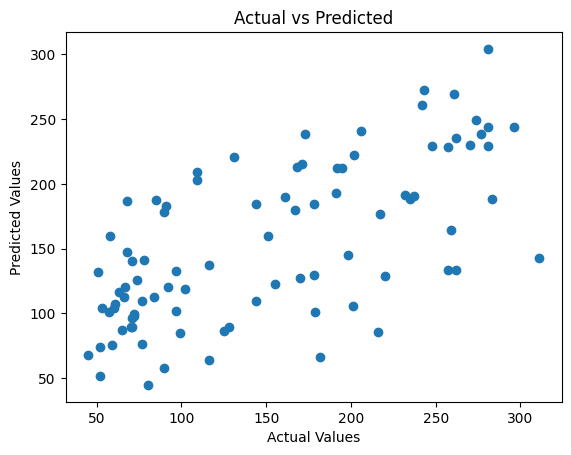

In [20]:
plt.scatter(Y_test , Y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")

plt.show()

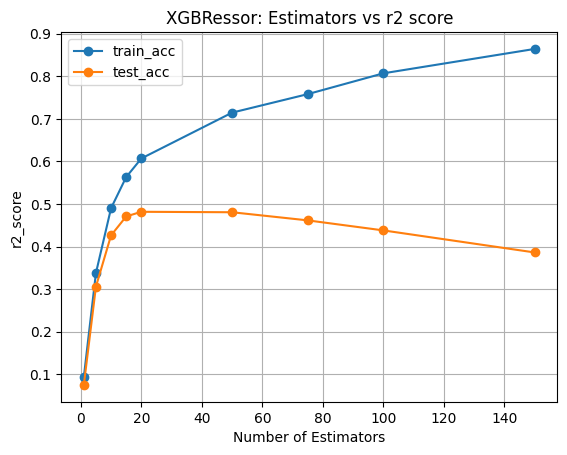

In [21]:
estimators = [1,5,10,15,20,50,75,100,150]

train_acc = []
test_acc  = []

for n in estimators:
    model=XGBRegressor(n_estimators = n, learning_rate=0.1, max_depth=3, random_state=42)
    model.fit(X_train,Y_train)

    train_acc.append(model.score(X_train,Y_train))
    test_acc.append(model.score(X_test,Y_test))

plt.plot(estimators, train_acc, marker='o', label="train_acc")
plt.plot(estimators, test_acc, marker='o', label="test_acc")

plt.xlabel("Number of Estimators")
plt.ylabel("r2_score")
plt.title("XGBRessor: Estimators vs r2 score")

plt.legend()
plt.grid()

plt.show()

In [22]:
from sklearn.model_selection import GridSearchCV

params = {"n_estimators":[50,100,150,200] , "learning_rate":[0.01,0.05,0.1,0.2] , "max_depth": [2,3,4,5]}

grid = GridSearchCV(XGBRegressor(random_state=42), params, scoring='neg_mean_squared_error', cv=5 , n_jobs=-1)
model1=grid.fit(X_train,Y_train)

In [23]:
print("Best Params:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
Best CV Score: -3223.376100931987


In [24]:
Y_pred = grid.predict(X_test)

mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 45.921775217806356
MSE: 3084.509319148772
RMSE: 55.5383589886195
R2: 0.5057342286741933
